# First Naive RDD

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [2]:
df_rdd = pd.read_csv('df_rdd_clean.csv')

## Rund first simple RDD

In [3]:
df_rdd

,code_commune,nuance,voix,election_year,tour,is_far_right,treat,d_50,skill_share_pre,skill_share_trend,delta_skill_share,pop_pre,pop_post,gender_gap_tertiary,no_diploma_share,far_right_participated,income_median,income_gini,unemployment_rate
0,1053,LUG,437,2014,t1,False,0,-2.409639,0.384403,0.028441,0.022447,27505.0,28030.0,-0.000504,0.615597,True,17694.500000,0.365057,17.997301
1,1053,LUG,388,2020,t1,False,0,-4.088756,0.406850,0.022447,0.022403,28030.0,28927.0,-0.005866,0.593150,True,18276.111111,0.375722,17.078005
2,2168,LDVG,335,2014,t1,False,0,-5.130327,0.322229,0.049262,0.016947,9906.0,10098.0,0.005124,0.677771,True,17063.666667,0.368367,22.861113
3,2168,LDVC,264,2020,t1,False,0,-5.420827,0.339176,0.016947,-0.009506,10098.0,10374.0,-0.031530,0.660824,True,17170.000000,0.387833,23.566623
4,2173,LDVD,315,2014,t2,False,0,-4.599702,0.275587,0.049451,0.039119,8266.0,8160.0,0.022809,0.724413,True,15662.666667,0.399675,24.051101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
832,95491,LDVD,386,2014,t1,False,0,-8.980798,0.500472,0.061387,0.044734,5293.0,5497.0,-0.017223,0.499528,True,NaN,NaN,8.661228
833,95563,LUMP,411,2014,t1,False,0,-5.092448,0.537022,0.048996,0.034063,10048.0,10403.0,0.002764,0.462978,True,28190.666667,0.309148,10.062158
834,95607,LUG,344,2008,t1,False,0,-3.158237,0.368726,0.024197,0.111584,16576.0,17293.0,0.007391,0.631274,True,22209.000000,0.309100,8.712611
835,95607,LUMP,462,2014,t2,False,0,-3.745754,0.480310,0.049311,0.035686,17293.0,17504.0,0.009470,0.519690,True,23755.090909,0.303520,10.358991


In [4]:
df_rdd_clean = df_rdd

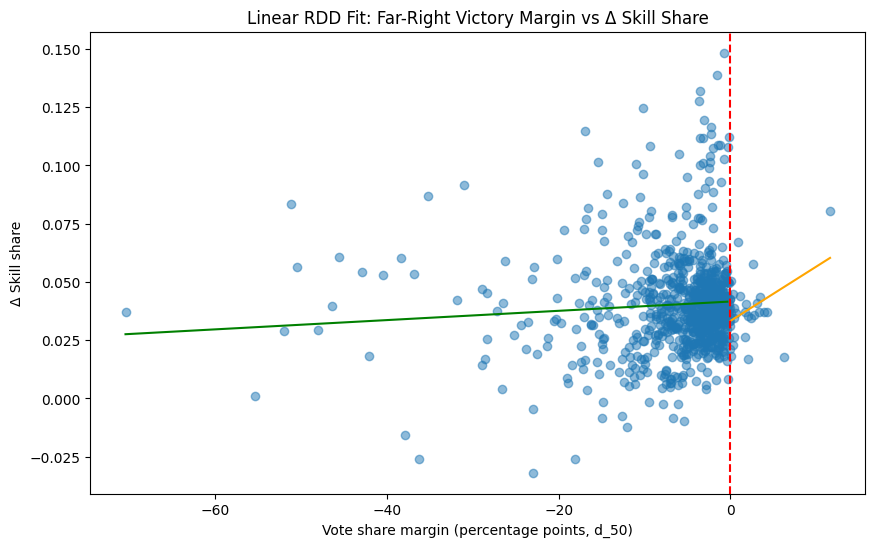

In [5]:
# First simple RDD Plot using matplotlib and statsmodels

# Fit simple linear RDD model (separate slopes each side of cutoff) 
df_rdd_clean['d_50_x_treat'] = df_rdd_clean['d_50'] * df_rdd_clean['treat']
X = sm.add_constant(df_rdd_clean[['d_50', 'treat', 'd_50_x_treat']])
model1 = sm.OLS(df_rdd_clean['delta_skill_share'], X).fit()

# Predict fitted lines on each side of the cutoff 
cutoff = 0.
x_vals = np.linspace(df_rdd_clean['d_50'].min(), df_rdd_clean['d_50'].max(), 200)

x_left = pd.DataFrame({'d_50': x_vals[x_vals <= cutoff], 'treat': 0})
x_left['d_50_x_treat'] = x_left['d_50'] * x_left['treat']
x_left = sm.add_constant(x_left, has_constant='add')

x_right = pd.DataFrame({'d_50': x_vals[x_vals > cutoff], 'treat': 1})
x_right['d_50_x_treat'] = x_right['d_50'] * x_right['treat']
x_right = sm.add_constant(x_right, has_constant='add')

y_pred_left = model1.predict(x_left)
y_pred_right = model1.predict(x_right)

#  Plot 
plt.figure(figsize=(10, 6))
plt.scatter(df_rdd_clean['d_50'], df_rdd_clean['delta_skill_share'], alpha=0.5)
plt.plot(x_left['d_50'], y_pred_left, color='green')
plt.plot(x_right['d_50'], y_pred_right, color='orange')
plt.axvline(cutoff, color='red', linestyle='--')
plt.title('Linear RDD Fit: Far-Right Victory Margin vs Δ Skill Share')
plt.xlabel('Vote share margin (percentage points, d_50)')
plt.ylabel('Δ Skill share')
plt.show()

## Select Bandwidth

In [6]:
from statsmodels.formula.api import ols
from rdrobust import rdbwselect, rdrobust

In [7]:


# Optimal bandwidth selection

# Uses the running variable (d_50) and outcome (delta_skill_share)
# c=0 -> cutoff is at 0 (already centered)
bw_result = rdbwselect(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0
)
print(bw_result)

Call: rdbwselect
Number of Observations:                   837
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

       h (left)  h (right)  b (left)  b (right)
mserd     1.648      1.648     2.757      2.757


In [8]:
# RD treatment effect estimation using the selected bandwidth

# rdrobust automatically selects its own optimal bandwidth internally (MSE-optimal by default),
# so you don't strictly need to feed bw_result in manually — but you can inspect/compare
rd_result = rdrobust(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0
)
print(rd_result)

Call: rdrobust

Sharp RD estimates using local polynomial regression.

Number of Observations:                   837
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

                                Left      Right
------------------------------------------------
Number of Observations           811         26
Number of Unique Obs.            811         26
Number of Effective Obs.         147         12
Bandwidth Estimation           1.648      1.648
Bandwidth Bias                 2.757      2.757
rho (h/b)                      0.598      0.598

Method             Coef.     S.E.   z-stat    P>|z|       95% CI      
-------------------------------------------------------------------------
Conventional      -0.011    0.009   -1.293   1.960e-01    [-0.028, 0.006]
Robust                 -        -   -1.333   1.

In [9]:
# Restrict sample to the MSE-optimal bandwidth from rdbwselect
bw = 1.648 # h (left) = h (right) from rdbwselect output

In [10]:
df_rdd_bw = df_rdd_clean[
    (df_rdd_clean['d_50'] >= -bw) & (df_rdd_clean['d_50'] <= bw)
].copy()

print(f"N observations within bandwidth: {len(df_rdd_bw)}")
print(f"N treated within bandwidth: {df_rdd_bw['treat'].sum()}")

N observations within bandwidth: 159
N treated within bandwidth: 12


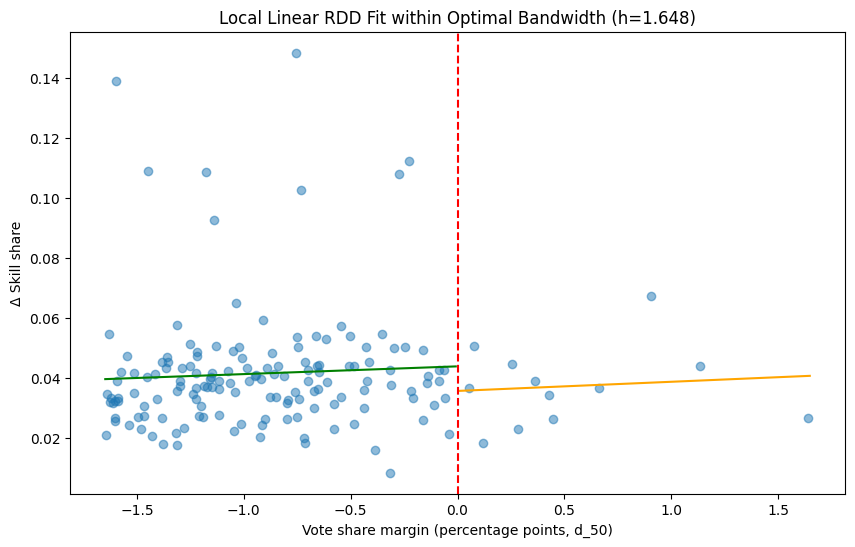

In [11]:
# Fit local linear RDD model within the bandwidth


df_rdd_bw['d_50_x_treat'] = df_rdd_bw['d_50'] * df_rdd_bw['treat']
X = sm.add_constant(df_rdd_bw[['d_50', 'treat', 'd_50_x_treat']])
model_bw = sm.OLS(df_rdd_bw['delta_skill_share'], X).fit()

# Predict fitted lines on each side of the cutoff, within the bandwidth only
cutoff = 0.
x_vals = np.linspace(-bw, bw, 200)

x_left = pd.DataFrame({'d_50': x_vals[x_vals <= cutoff], 'treat': 0})
x_left['d_50_x_treat'] = x_left['d_50'] * x_left['treat']
x_left = sm.add_constant(x_left, has_constant='add')

x_right = pd.DataFrame({'d_50': x_vals[x_vals > cutoff], 'treat': 1})
x_right['d_50_x_treat'] = x_right['d_50'] * x_right['treat']
x_right = sm.add_constant(x_right, has_constant='add')

y_pred_left = model_bw.predict(x_left)
y_pred_right = model_bw.predict(x_right)

#  Plot
plt.figure(figsize=(10, 6))
plt.scatter(df_rdd_bw['d_50'], df_rdd_bw['delta_skill_share'], alpha=0.5)
plt.plot(x_left['d_50'], y_pred_left, color='green')
plt.plot(x_right['d_50'], y_pred_right, color='orange')
plt.axvline(cutoff, color='red', linestyle='--')
plt.title(f'Local Linear RDD Fit within Optimal Bandwidth (h={bw})')
plt.xlabel('Vote share margin (percentage points, d_50)')
plt.ylabel('Δ Skill share')
plt.show()

## Regress naive OLS for RDD

In [12]:
from statsmodels.formula.api import ols

In [13]:
# interaction term: allows the slope of d_50 to differ on each side of the cutoff ──
# Similar the specification in the plot (standard sharp-RDD practice)
model1 = ols('delta_skill_share ~ d_50 * treat', data=df_rdd_clean).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:      delta_skill_share   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     2.086
Date:                Fri, 28 Aug 2026   Prob (F-statistic):              0.101
Time:                        15:13:00   Log-Likelihood:                 2028.6
No. Observations:                 837   AIC:                            -4049.
Df Residuals:                     833   BIC:                            -4030.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0416      0.001     42.327      0.0

In [14]:
# RD point estimate + confidence interval using rdrobust library
rd_result = rdrobust(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0,  # dont know 
    p=1,  # local linear, matches rdplot specification
    h=bw  # my rdwselect bandwidth which I used to restrict the sample for the linear regression above
)
print(rd_result)

Call: rdrobust

Sharp RD estimates using local polynomial regression.

Number of Observations:                   837
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                   Manual
Var-Cov Estimator:                         NN

                                Left      Right
------------------------------------------------
Number of Observations           811         26
Number of Unique Obs.            811         26
Number of Effective Obs.         147         12
Bandwidth Estimation           1.648      1.648
Bandwidth Bias                 1.648      1.648
rho (h/b)                        1.0        1.0

Method             Coef.     S.E.   z-stat    P>|z|       95% CI      
-------------------------------------------------------------------------
Conventional      -0.011    0.009   -1.293   1.960e-01    [-0.028, 0.006]
Robust                 -        -   -0.304   7.

## Using rdrobust library to plot using Bins

In [15]:
from rdrobust import rdplot
import statsmodels.formula.api as smf

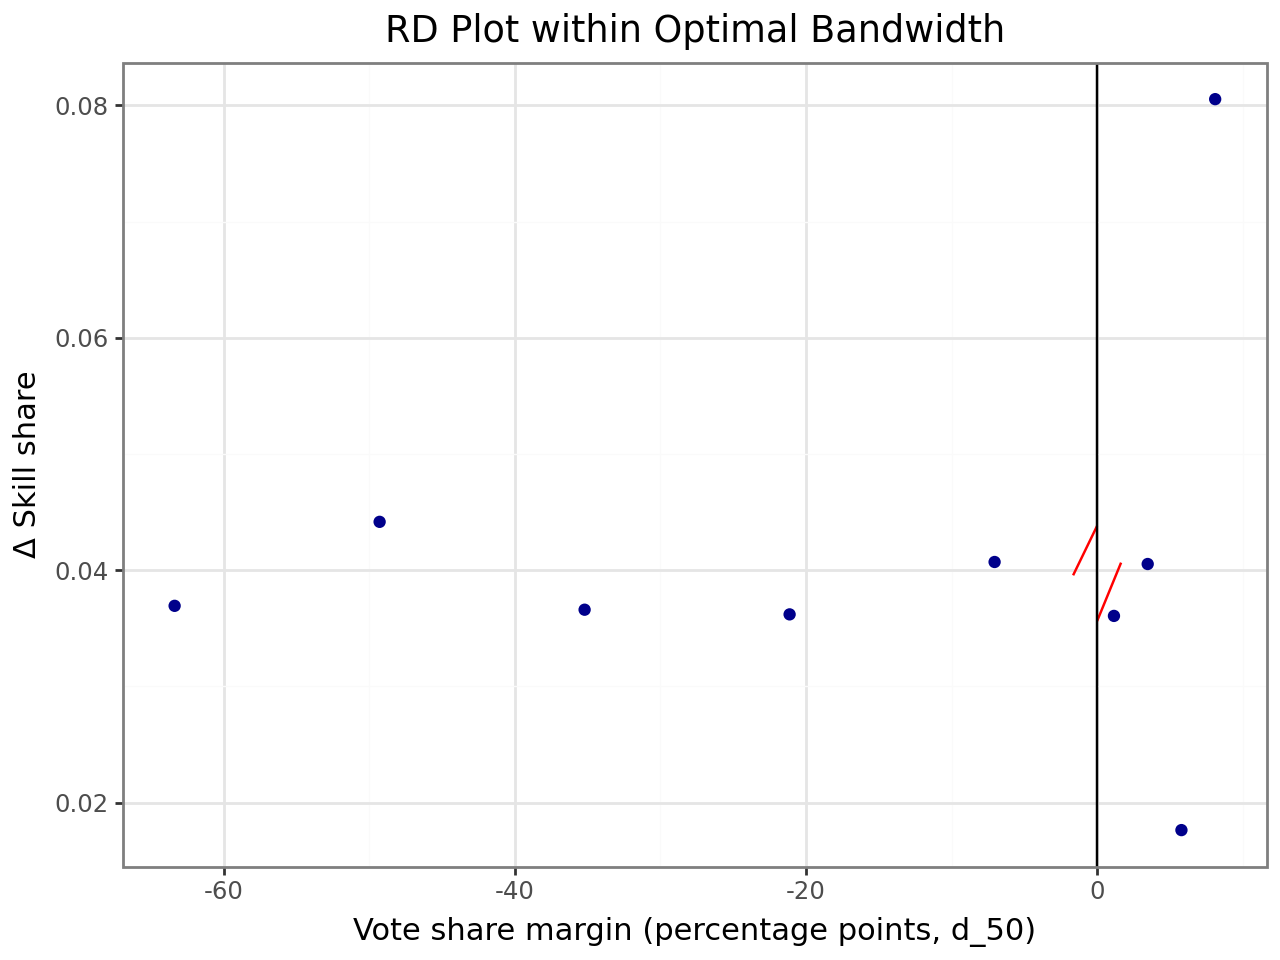

Call: rdplot
Number of Observations:                   837
Kernel:                               Uniform
Polynomial Order Est. (p):                  1

                                Left      Right
------------------------------------------------
Number of Observations           811         26
Number of Effective Obs          147         12
Bandwidth poly. fit (h)        1.648      1.648
Number of bins scale               1          1
Bins Selected                      5          5
Average Bin Length            14.084      2.318
Median Bin Length             14.084      2.318
IMSE-optimal bins                6.0        5.0
Mimicking Variance bins         12.0        4.0

Relative to IMSE-optimal:
Implied scale                  0.833        1.0
WIMSE variance weight          0.633        0.5
WIMSE bias weight              0.367        0.5

In [16]:
# ── Standard rdplot: automatically bins, fits local polynomial, and plots ──
# p=1 -> linear fit (matches your model_bw specification)
# This uses the FULL sample (df_rdd_clean), not just the bandwidth-restricted one --
# rdplot is a descriptive/diagnostic tool and typically shown on the wider sample,
# with the bandwidth from rdbwselect used only for the rdrobust estimation itself
rdplot(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0,
    p=1,
    h=bw,  # manually restrict to the rdbwselect bandwidth
    nbins=(5, 5),  # 5 bins left, 5 bins right (input from Gabriel)
    title='RD Plot within Optimal Bandwidth',
    x_label='Vote share margin (percentage points, d_50)',
    y_label='Δ Skill share'
)

## first diff in disc model